# Κώδικας GNSS: σημειακός προσδιορισμός θέσης (GPS)

Στόχος: εκτίμηση των **X, Y, Z** του σταθμού, ενός σφάλματος χρονομέτρου
για κάθε εποχή και της **ζενίθιας υγρής τροποσφαιρικής καθυστέρησης (ZWD)**
ανά δύο ώρες.  Χρησιμοποιούμε μόνο παρατηρήσεις *κώδικα*, όχι φάσης.

Ο ιονοσφαιρικά απαλλαγμένος συνδυασμός είναι

\[
P_{IF}=\frac{f_1^2 P_1-f_2^2 P_2}{f_1^2-f_2^2}.
\]

Μετά τη διόρθωση OSB και κεραιών, το μοντέλο παρατήρησης (σε μέτρα) είναι

\[
P_{IF}^{corr}+c\,\delta t_s
=\|\mathbf r_s(t_{tx})-[\mathbf r_{marker}+\mathbf d_{ARP}+\mathbf d_{SET}(t)]\|
+c\,\delta t_r(t)+\Delta\rho_{Sagnac}+\Delta\rho_{rel}
+ZHD\,m_h+ZWD(t)\,m_w+\varepsilon.
\]

Η ZWD εκτιμάται *τμηματικά γραμμικά*: δύο γειτονικοί κόμβοι ανά παρατήρηση,
απόσταση κόμβων 2 ωρών.  Ο σταθμός αναφέρεται στον **marker** του RINEX.
Αντιμετωπίζουμε το SP3 ως θέση του κέντρου μάζας (CoM) του δορυφόρου.

**Ρητές διδακτικές προσεγγίσεις:** το δορυφορικό +Z δείχνει προς το γεώκεντρο,
επομένως εφαρμόζουμε μόνο το ακτινικό (Z) ANTEX PCO, όχι X/Y ή δορυφορικό PCV.
Δεν εφαρμόζουμε ocean loading, phase wind-up ή διορθώσεις δεύτερης τάξης.

## 1. Αρχεία δεδομένων και επιλογές

In [11]:
from os.path import join

# This notebook lives in JupyterLab/gnss/beta/.
data_path = "../../../data"
rinex_path = join(data_path, "DYNG00GRC_R_20240010000_01D_30S_MO.rnx")
sp3_path = join(data_path, "COD0MGXFIN_20240010000_01D_05M_ORB.SP3")
vmf3_path = join(data_path, "y2024.vmf3_g")
bias_path = join(data_path, "COD0MGXFIN_20240010000_01D_01D_OSB.BIA")
atx_path = join(data_path, "igs20.atx")

# Keep these toggles visible to students: each has a physical meaning.
EVERY_SEC = 180
ELEVATION_CUTOFF_DEG = 3.0
ZWD_EVERY_HOURS = 2.0
SIGMA_CODE_M = 5.0
APPLY_SOLID_EARTH_TIDES = True
APPLY_SATELLITE_NADIR_PCO = True
EXCLUDE_SATELLITES = set()

## 2. Απλές εισαγωγές και επιλογή δορυφορικού συστήματος

In [12]:
from collections import Counter
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from dsoclasses.orbits.interpolator import Sp3Interpolator
from dsoclasses.rinex.gnss.rinex import GnssRinex, fetch
from dsoclasses.gnss import algorithms as alg
from dsoclasses.gnss import systems as gs
from dsoclasses.gnss.atx import Atx
from dsoclasses.gnss.biasx import Bsinex
from dsoclasses.gnss.code_zwd import solve_code_zwd
from dsoclasses.troposphere.vmf3 import SiteVmf3
from dsoclasses.geodesy import transformations
from dsoclasses.geodesy.earth_models import solid_earth_tide_xyz
from dsoclasses.time.astropy_time import to_astropy_time

In [13]:
# A GNSS satellite identifier always includes its constellation letter.
SYSTEM = 'G'
FREQ1_ATX, FREQ2_ATX = 'G01', 'G02'
CODE1 = ('C1W', 'C1C', 'C1X', 'C1L')
CODE2 = ('C2W', 'C2C', 'C2D', 'C2P', 'C2X', 'C2S', 'C2L')
ALLOW_MISSING_SATELLITE_OSB = False

def satellite_frequencies(sat):
    # MHz are sufficient: only ratios of squared frequencies are used.
    return gs.GPS_L1_FREQ, gs.GPS_L2_FREQ

## 3. RINEX, SP3 και διορθώσεις κεραιών/ατμόσφαιρας

In [14]:
rnx = GnssRinex(rinex_path)
intrp = Sp3Interpolator.from_sp3(
    sp3_path, [SYSTEM], interval_in_sec=2400,
    min_data_pts=8, stencil_pts=8, itype='Barycentric',
)

# The source readers deliberately do NOT convert between time systems.
# Reject mismatched time tags instead of accidentally treating UTC/GLO as GPS.
rinex_scale = (rnx.time_sys or '').strip().upper()
sp3_scale = intrp.time_system().strip().upper()
print('RINEX/SP3 time scales:', rinex_scale, '/', sp3_scale)
if rinex_scale != sp3_scale:
    raise ValueError('RINEX and SP3 have different time scales; convert the '
                     'epoch labels explicitly before positioning')
print('RINEX first epoch as UTC (Astropy):',
      to_astropy_time(rnx.time_first_obs, rinex_scale).utc.isot)

marker_xyz = np.array(rnx.approx_cartesian(), dtype=float)
latitude, longitude, height_m = transformations.car2ell(*marker_xyz)
site_id = rnx.marker_name[:4].upper()  # VMF3 site-wise stations use 4-char IDs.

vmf = SiteVmf3(vmf3_path, site_list=[site_id])
osb = Bsinex(bias_path)
antex = Atx(atx_path)
receiver_antenna = antex.get_noazi(rnx.antenna_type,
                                    [FREQ1_ATX, FREQ2_ATX])

# RINEX header ANTENNA: DELTA H/E/N = marker -> ARP, metres.
if not all(hasattr(rnx, key) for key in ('dh', 'de', 'dn')):
    raise ValueError('RINEX lacks ANTENNA: DELTA H/E/N; marker/ARP offset unknown')
marker_to_arp_ecef = transformations.geodetic2lvlh(latitude, longitude) @ np.array(
    [rnx.de, rnx.dn, rnx.dh], dtype=float
)

print('Station:', rnx.marker_name, ' / antenna:', rnx.antenna_type)
print('RINEX observables:', rnx.obscodes.get(SYSTEM, []))
print('Marker -> ARP offset [m]:', marker_to_arp_ecef)

RINEX/SP3 time scales: GPS / GPS
RINEX first epoch as UTC (Astropy): 2023-12-31T23:59:42.000
Station: DYNG  / antenna: TRM59800.00     NONE
RINEX observables: ['C1C', 'L1C', 'D1C', 'S1C', 'C1W', 'S1W', 'C2W', 'L2W', 'D2W', 'S2W', 'C2L', 'L2L', 'D2L', 'S2L', 'C5Q', 'L5Q', 'D5Q', 'S5Q', 'C1L', 'L1L', 'D1L', 'S1L']
Marker -> ARP offset [m]: [1.45192864 0.64438977 1.24458388]


/tmp/ipykernel_14179/209620561.py:22: RuntimeWarning: Skipped 2 VMF3 record(s) with nonpositive wet mapping coefficient a_w in ../../../data/y2024.vmf3_g; first: DYNG at 2024-02-12 06:00:00 (line 100906, a_w=-1.5e-06). Interpolation across missing six-hour records is not permitted.
  vmf = SiteVmf3(vmf3_path, site_list=[site_id])


## 4. Συλλογή διορθωμένων παρατηρήσεων κώδικα

In [15]:
from collections import Counter

# Collect only ordinary code observations with complete required corrections.
# Expected missing data are counted; programming mistakes remain visible.
raw_obs = []
skip_reasons = Counter()
missing_osb = Counter()
num_epochs = 0
last_used_astropy_time = None
first_epoch_astropy = to_astropy_time(rnx.time_first_obs, rinex_scale)
knot_spacing_s = ZWD_EVERY_HOURS * 3600
elevation_cutoff = np.deg2rad(ELEVATION_CUTOFF_DEG)


def code_osb_metres(sat, code, t):
    try:
        return osb.code_bias_m(sat, code, t)
    except (LookupError, ValueError) as exc:
        if not ALLOW_MISSING_SATELLITE_OSB:
            raise
        # Some GLONASS products have no OSB for particular FDMA signals.
        # In that case our demonstrator deliberately uses zero but REPORTS it.
        missing_osb[(sat, code)] += 1
        return 0.0


for block in rnx:
    t = block.t()
    astro_t = to_astropy_time(t, rinex_scale)
    elapsed_s = (astro_t - first_epoch_astropy).to_value('s')
    if (last_used_astropy_time is not None and
            (astro_t - last_used_astropy_time).to_value('s') < EVERY_SEC):
        continue
    if elapsed_s < 0:
        continue

    # One solid-Earth-tide displacement per epoch, not per satellite.
    tide_xyz = (solid_earth_tide_xyz(marker_xyz, t, rinex_scale)
                if APPLY_SOLID_EARTH_TIDES else np.zeros(3))
    station_displacement = marker_to_arp_ecef + tide_xyz
    approx_arp = marker_xyz + station_displacement

    # Linear interpolation between the surrounding two-hour ZWD knots.
    k, remainder_s = divmod(elapsed_s, knot_spacing_s)
    alpha = remainder_s / knot_spacing_s
    zwd_basis = [(int(k), 1.0 - alpha), (int(k) + 1, alpha)]
    candidates = []

    for sat, obs in block.filter_satellite_system(SYSTEM, False):
        if sat in EXCLUDE_SATELLITES:
            continue
        try:
            first, code1 = fetch(obs, *CODE1)
            second, code2 = fetch(obs, *CODE2)
            f1, f2 = satellite_frequencies(sat)
            divisor = f1*f1 - f2*f2

            p1 = float(first['value']) - code_osb_metres(sat, code1, t)
            p2 = float(second['value']) - code_osb_metres(sat, code2, t)

            xs, ys, zs, satellite_clock_s, tau = alg.sat_at_emission_time(
                approx_arp, t, intrp, sat)
            satellite_xyz = np.array([xs, ys, zs])
            _, az, el = transformations.azele(satellite_xyz, approx_arp)
            if el < elevation_cutoff:
                skip_reasons['Below elevation cutoff'] += 1
                continue

            # Receiver ANTEX PCO + NOAZI PCV: already in metres.
            p1 += receiver_antenna.range_correction_m(FREQ1_ATX, az, el)
            p2 += receiver_antenna.range_correction_m(FREQ2_ATX, az, el)

            if APPLY_SATELLITE_NADIR_PCO:
                # Approximation: satellite body +Z points to geocentre.
                # The X/Y PCO components and satellite PCV are not modeled.
                p1 += antex.satellite_nadir_range_correction_m(
                    sat, FREQ1_ATX, t, satellite_xyz, approx_arp,
                    travel_time_s=tau)
                p2 += antex.satellite_nadir_range_correction_m(
                    sat, FREQ2_ATX, t, satellite_xyz, approx_arp,
                    travel_time_s=tau)

            p_iono_free = (f1*f1*p1 - f2*f2*p2) / divisor
            meteo = vmf.vmf3(site_id, latitude, longitude, el, t)
            relativity = alg.relativistic_range_term(
                t, intrp, sat, travel_time_s=tau)
            sagnac = alg.sagnac_range_term(satellite_xyz, approx_arp)

            model_values = [p_iono_free, satellite_clock_s, relativity,
                            sagnac, meteo['zhd'], meteo['zwd'],
                            meteo['mfh'], meteo['mfw']]
            if not (np.all(np.isfinite(model_values)) and
                    np.all(np.isfinite(satellite_xyz))):
                raise ValueError('Non-finite code observation or model correction')

            candidates.append({
                't': t, 'sat': sat, 'p3': p_iono_free, 'code1': code1, 'code2': code2,
                'rsat': satellite_xyz, 'csat': satellite_clock_s,
                'el': el, 'dT': meteo, 'drel': relativity,
                'dsagnac': sagnac, 'zwd_basis': zwd_basis,
                'station_displacement_m': station_displacement,
            })
        except (LookupError, KeyError, ValueError, RuntimeError, ArithmeticError) as exc:
            skip_reasons[f'{type(exc).__name__}: {exc}'] += 1

    # A standalone clock epoch with too few satellites is poorly constrained.
    if len(candidates) < 4:
        skip_reasons['Epoch with fewer than four complete code satellites'] += 1
        continue
    for candidate in candidates:
        candidate['nepoch'] = num_epochs
        raw_obs.append(candidate)
    last_used_astropy_time = astro_t
    num_epochs += 1

print(f'Accepted {len(raw_obs)} code observations in {num_epochs} epochs')
for reason, count in skip_reasons.most_common(12):
    print(f'  skipped {count:5d}  {reason}')

code_pairs = Counter(
    (obs['code1'], obs['code2'])
    for obs in raw_obs
)
print("Code combinations actually used:")
for pair, count in code_pairs.most_common():
    print(f"{pair[0]:4s} + {pair[1]:4s}: {count:5d}")

if missing_osb:
    print('WARNING: missing satellite OSB values explicitly set to zero:')
    for key, count in missing_osb.most_common(10):
        print(f'  {key}: {count} observations')
if not raw_obs:
    raise RuntimeError('No valid code observations; check the skip summary, '
                       'signal codes, epoch scales and correction-file coverage')

Accepted 4258 code observations in 416 epochs
  skipped   130  Below elevation cutoff
  skipped    25  LookupError: No valid observable found among ('C1W', 'C1C', 'C1X', 'C1L')
  skipped    15  LookupError: No valid observable found among ('C2W', 'C2C', 'C2D', 'C2P', 'C2X', 'C2S', 'C2L')
  skipped     7  ValueError: G27 has no finite satellite clock at emission
  skipped     6  Epoch with fewer than four complete code satellites
  skipped     5  ValueError: G01 has no finite satellite clock at emission
  skipped     5  ValueError: G02 has no finite satellite clock at emission
  skipped     5  ValueError: G03 has no finite satellite clock at emission
  skipped     5  ValueError: G08 has no finite satellite clock at emission
  skipped     5  ValueError: G10 has no finite satellite clock at emission
  skipped     5  ValueError: G14 has no finite satellite clock at emission
  skipped     5  ValueError: G21 has no finite satellite clock at emission
Code combinations actually used:
C1W  + C2

## 5. Κοινός υπολογισμός XYZ, εποχιακών clocks και ZWD

In [7]:
# dsoclasses solves the nonlinear weighted least-squares equations and checks
# the rank, convergence, rejected observations and final post-fit residuals.
solution = solve_code_zwd(
    raw_obs, marker_xyz, num_epochs, sigma0=SIGMA_CODE_M,
    max_iterations=10, max_rejections=3, rejection_sigma=4.0,
)
estimated_marker_xyz = solution.parameters[:3]
final_residuals = solution.residuals
accepted = solution.weights > 0

print('Estimated marker ECEF XYZ [m]:', estimated_marker_xyz)
print('RINEX approximate marker XYZ [m]:', marker_xyz)
print('Difference to RINEX approximate XYZ [m]:', estimated_marker_xyz - marker_xyz)
print(f'Iterations: {solution.iterations}, rank: {solution.rank}, '
      f'unit-weight sigma: {solution.sigma_hat0:.3f}')
print(f'Final post-fit residual RMS [m]: '
      f'{np.sqrt(np.mean(final_residuals[accepted]**2)):.3f}')
print(f'Rejected observations: {int(np.count_nonzero(~accepted))}')

# RINEX positions are APPROXIMATE: this difference is not a position error
# against an independently surveyed reference point.

Estimated marker ECEF XYZ [m]: [4595220.24764036 2039434.39922713 3912625.96388743]
RINEX approximate marker XYZ [m]: [4595218.5637 2039433.4368 3912624.7622]
Difference to RINEX approximate XYZ [m]: [1.68394036 0.96242713 1.20168743]
Iterations: 2, rank: 432, unit-weight sigma: 0.052
Final post-fit residual RMS [m]: 0.766
Rejected observations: 0


## 6. Διάγνωση: υπολείμματα, χρονομέτρο και ZWD

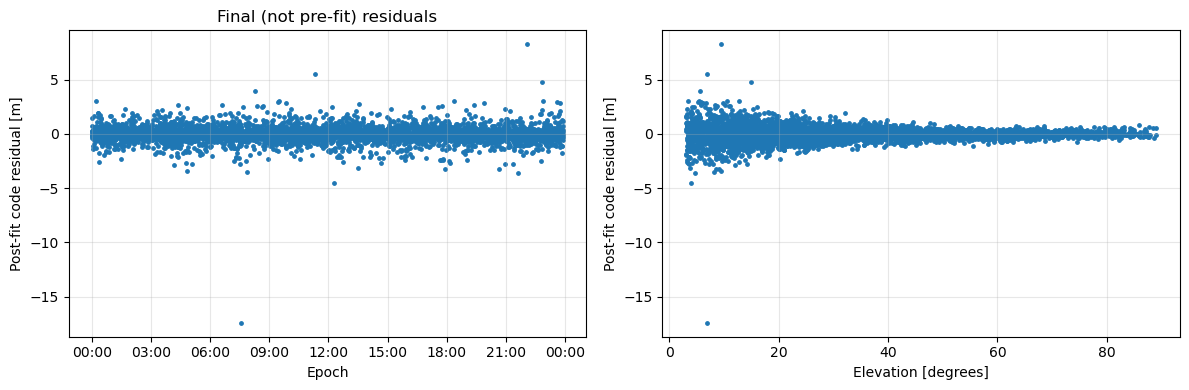

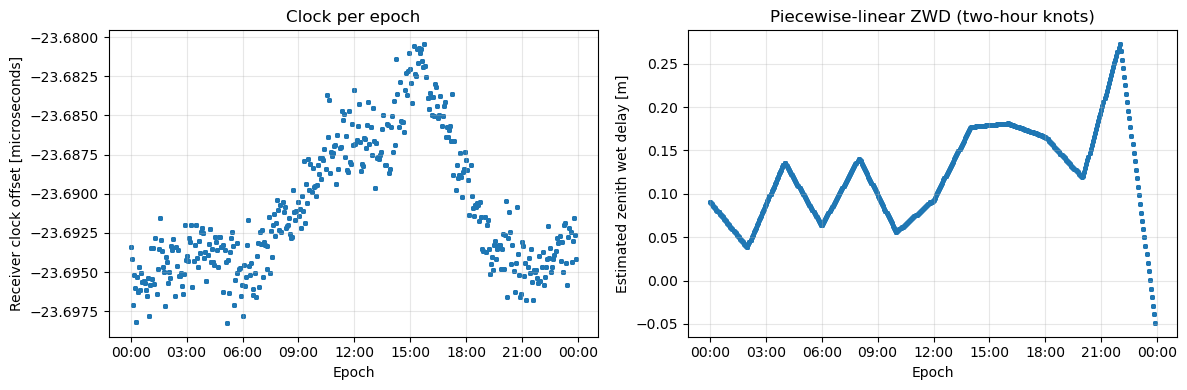

In [8]:
# Display plot epochs in UTC, regardless of the RINEX time scale.
epochs_plot = [to_astropy_time(obs['t'], rinex_scale).utc.datetime
               for obs in raw_obs]
elevations_deg = [np.degrees(obs['el']) for obs in raw_obs]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(np.array(epochs_plot)[accepted], final_residuals[accepted], s=6)
ax[0].set(xlabel='Epoch', ylabel='Post-fit code residual [m]',
          title='Final (not pre-fit) residuals')
ax[0].xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax[1].scatter(np.array(elevations_deg)[accepted], final_residuals[accepted], s=6)
ax[1].set(xlabel='Elevation [degrees]', ylabel='Post-fit code residual [m]')
for axis in ax:
    axis.grid(alpha=.3)
fig.tight_layout()
plt.show()

clock_us = np.array([solution.parameters[3 + o['nepoch']] / gs.C * 1e6
                     for o in raw_obs])
zwd_m = np.array([
    sum(weight * solution.parameters[3 + num_epochs + k]
        for k, weight in o['zwd_basis'])
    for o in raw_obs
])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(epochs_plot, clock_us, s=6)
ax[0].set(ylabel='Receiver clock offset [microseconds]', title='Clock per epoch')
ax[1].scatter(epochs_plot, zwd_m, s=6)
ax[1].set(ylabel='Estimated zenith wet delay [m]',
          title='Piecewise-linear ZWD (two-hour knots)')
for axis in ax:
    axis.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
    axis.set_xlabel('Epoch')
    axis.grid(alpha=.3)
fig.tight_layout()
plt.show()

### Τι δείχνει η λύση;

- Κάθε εποχή έχει δικό της άγνωστο σφάλμα χρονομέτρου δέκτη.
- Η ZWD **εκτιμάται**, δεν κρατείται σταθερή. Η ZHD και οι VMF3 mapping
  functions θεωρούνται γνωστές.
- Η θέση αναφέρεται στον **marker**, όχι στο antenna phase centre:
  η μετατόπιση marker→ARP και η κίνηση λόγω solid Earth tide συμμετέχουν
  στο μοντέλο.
- Το SP3 θεωρείται τροχιά του CoM. Το δορυφορικό PCO περιλαμβάνει μόνο
  τη ναδιρική συνιστώσα Z· δεν μοντελοποιείται πλήρης attitude.
- Οι αριθμοί παρατηρήσεων που απορρίφθηκαν εμφανίζονται παραπάνω.
  Απορρίψεις λόγω έλλειψης OSB ή γεωμετρικών δεδομένων **δεν κρύβονται**.

Το RINEX `APPROX POSITION XYZ` δεν είναι ανεξάρτητη γεωδαιτική λύση,
άρα η διαφορά του από τις εκτιμώμενες συντεταγμένες δεν είναι ακριβής
εκτίμηση του σφάλματος της λύσης.

## 7. Εξωτερικός έλεγχος με συντεταγμένες SINEX

Χρησιμοποιούμε τις **STA(X,Y,Z)** και **VEL(X,Y,Z)** του σταθμού DYNG
από το μικρό αρχείο `ITRF2020-IGS-TRF.SSC` (χωρίς covariance).
Προεκτείνουμε γραμμικά τις συντεταγμένες στην εποχή παρατήρησης και
συγκρίνουμε με την εκτιμημένη θέση του **marker**, όχι με την αρχική
προσεγγιστική θέση του RINEX. Το `extrapolate_after_last=True` είναι
σκόπιμη επιλογή: οι μετρήσεις ITRF2020 σταματούν πριν από το 2024.

Οι διαφορές εκφράζονται σε ECEF και σε τοπικό **East, North, Up**.
**Προσοχή:** ITRF2020 και IGS20 δεν είναι απολύτως ταυτόσημα· δεν
εφαρμόζουμε εδώ μετασχηματισμό υλοποίησης πλαισίου, μη γραμμικές κινήσεις,
σεισμικά άλματα ή εποχιακά σήματα. Πρόκειται για ανεξάρτητο
εκπαιδευτικό έλεγχο, όχι πλήρη γεωδαιτική επικύρωση.

In [10]:
from dsoclasses.sinex.sinex import extract_sinex_coordinates

# A compact official no-covariance alternative to the very large SNX.gz.
# If you made a DYNG-only extract, use "DYNG_ITRF2020.snx" instead.
snx_path = join(data_path, "ITRF2020-IGS-TRF.SSC")

# A SINEX date is a UTC-like calendar epoch, not a GNSS GPS label.
reference_epoch = to_astropy_time(rnx.time_first_obs, rinex_scale).utc.datetime
reference = extract_sinex_coordinates(
    snx_path, [site_id], reference_epoch, extrapolate_after_last=True
)[site_id]

reference_xyz = np.array([reference[axis] for axis in 'XYZ'], dtype=float)
difference_xyz = estimated_marker_xyz - reference_xyz
ref_lat, ref_lon, _ = transformations.car2ell(*reference_xyz)
difference_enu = transformations.geodetic2lvlh(ref_lat, ref_lon).T @ difference_xyz

print('SINEX solution number:', reference['soln'])
print('Forward extrapolation past last observation interval:',
      reference['extrapolated_after_last'])
print('SINEX ITRF2020 marker XYZ [m]:', reference_xyz)
print('Code-only minus SINEX XYZ [m]:', difference_xyz)
print('Code-only minus SINEX ENU [m] (East, North, Up):', difference_enu)
print(f'3D difference: {np.linalg.norm(difference_xyz):.3f} m')

SINEX solution number: 3
Forward extrapolation past last observation interval: True
SINEX ITRF2020 marker XYZ [m]: [4595220.06008699 2039434.22651429 3912625.87232351]
Code-only minus SINEX XYZ [m]: [0.18755337 0.17271284 0.09156392]
Code-only minus SINEX ENU [m] (East, North, Up): [ 0.08178103 -0.0768614   0.24656466]
3D difference: 0.271 m
